In [1]:
# imports
import pandas as pd
import statsmodels.formula.api as smf
import os
import matplotlib.pyplot as plt

##### Create regression dataframe

In [2]:
# load the scored reviews
df = pd.read_csv('../data/processed/rmp_scored.csv')

# reviews that mention both leniency and teaching, minus "Other" department group
dict_df = df[(df['leniency_mentioned'] == 1) & (df['teaching_mentioned'] == 1)]
dict_df = dict_df[dict_df['dept_group'] != 'Other'].copy()

# standardize the two scores so their coefficients can be compared
dict_df['leniency_z'] = (dict_df['leniency_net'] - dict_df['leniency_net'].mean()) / dict_df['leniency_net'].std()
dict_df['teaching_z'] = (dict_df['teaching_net'] - dict_df['teaching_net'].mean()) / dict_df['teaching_net'].std()

print("Reviews:", len(dict_df))

Reviews: 6050


##### Dictionary regression model

In [3]:
# quality is predicted from leniency, teaching, and difficulty, controlling for department and school
# humanities is the comparison group -> H4 comparison
formula = "quality ~ leniency_z + teaching_z + difficulty + C(dept_group, Treatment('Humanities')) + C(school)"

# cluster standard errors by professor, since reviews of the same professor are not independent
dict_model = smf.ols(formula, data=dict_df).fit(cov_type='cluster', cov_kwds={'groups': dict_df['professor_id']})
print(dict_model.summary())

# tests whether leniency and teaching coefficients are actually different (H3)
print(dict_model.t_test('leniency_z = teaching_z'))

                            OLS Regression Results                            
Dep. Variable:                quality   R-squared:                       0.419
Model:                            OLS   Adj. R-squared:                  0.418
Method:                 Least Squares   F-statistic:                     399.1
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:52:37   Log-Likelihood:                -8748.6
No. Observations:                6050   AIC:                         1.752e+04
Df Residuals:                    6039   BIC:                         1.759e+04
Df Model:                          10                                         
Covariance Type:              cluster                                         
                                                               coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------

Using the dictionary scores on 6,050 reviews, both leniency and teaching raise ratings, but teaching has a much bigger effect. One standard deviation better teaching adds about 0.7 stars, compared to 0.19 stars for leniency, and the t-test shows this difference is significant (p < 0.001). Each extra point of difficulty lowers the rating by about 0.27 stars. STEM professors are not rated differently from humanities professors once these are controlled for (p = 0.66). The model explains about 42% of the variation in ratings.

This supports H1 and H2, rejects H3 in the opposite direction (teaching matters more than leniency), and does not support H4.

##### Robustness checks

In [4]:
# same model without difficulty, since difficulty overlaps with leniency
formula_no_diff = "quality ~ leniency_z + teaching_z + C(dept_group, Treatment('Humanities')) + C(school)"
no_diff_model = smf.ols(formula_no_diff, data=dict_df).fit(cov_type='cluster', cov_kwds={'groups': dict_df['professor_id']})
print(no_diff_model.params[['leniency_z', 'teaching_z']])

# all reviews, not just ones that mention both concepts
all_df = df[df['dept_group'] != 'Other'].copy()
all_df['leniency_z'] = (all_df['leniency_net'] - all_df['leniency_net'].mean()) / all_df['leniency_net'].std()
all_df['teaching_z'] = (all_df['teaching_net'] - all_df['teaching_net'].mean()) / all_df['teaching_net'].std()

# mention flags keep "not mentioned" separate from a neutral score of 0
formula_all = "quality ~ leniency_z + teaching_z + leniency_mentioned + teaching_mentioned + difficulty + C(dept_group, Treatment('Humanities')) + C(school)"
all_model = smf.ols(formula_all, data=all_df).fit(cov_type='cluster', cov_kwds={'groups': all_df['professor_id']})
print(all_model.params[['leniency_z', 'teaching_z', 'difficulty']])

leniency_z    0.315588
teaching_z    0.722985
dtype: float64
leniency_z    0.090646
teaching_z    0.507492
difficulty   -0.445121
dtype: float64


Without difficulty, the leniency effect rises from 0.19 to 0.32 stars while teaching barely changes. This means part of the leniency effect overlaps with difficulty, since lenient reviews also tend to describe easier classes. Using all 55,773 reviews, the coefficients are smaller because most reviews have a score of 0, but teaching is still about five times larger than leniency. The main result is not caused by only using reviews that mention both concepts.

##### LLM regression

In [5]:
# load the llm scores and rename columns so they don't conflict when merging
llm = pd.read_csv('../data/processed/llm_scores.csv')
llm = llm.rename(columns={'leniency': 'llm_leniency', 'teaching': 'llm_teaching'})

# add the ratings, department, and school to each llm scored review
llm_df = llm.merge(df, on='review_id')

# reviews the llm scored for both, without the "Other" group
llm_df = llm_df[llm_df['llm_leniency'].notna() & llm_df['llm_teaching'].notna()]
llm_df = llm_df[llm_df['dept_group'] != 'Other'].copy()

# standardize the llm scores the same way as the dictionary scores
llm_df['leniency_z'] = (llm_df['llm_leniency'] - llm_df['llm_leniency'].mean()) / llm_df['llm_leniency'].std()
llm_df['teaching_z'] = (llm_df['llm_teaching'] - llm_df['llm_teaching'].mean()) / llm_df['llm_teaching'].std()

# same model as the dictionary version
llm_model = smf.ols(formula, data=llm_df).fit(cov_type='cluster', cov_kwds={'groups': llm_df['professor_id']})
print("Reviews:", len(llm_df))
print(llm_model.summary())
print(llm_model.t_test('leniency_z = teaching_z'))

Reviews: 2616
                            OLS Regression Results                            
Dep. Variable:                quality   R-squared:                       0.696
Model:                            OLS   Adj. R-squared:                  0.695
Method:                 Least Squares   F-statistic:                     591.4
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:52:38   Log-Likelihood:                -3064.6
No. Observations:                2616   AIC:                             6151.
Df Residuals:                    2605   BIC:                             6216.
Df Model:                          10                                         
Covariance Type:              cluster                                         
                                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------

Using the LLM scores on 2,616 reviews, the leniency effect is the same as the dictionary version (0.19 stars), while the teaching effect is much larger (1.04 stars). Teaching is again significantly larger than leniency (p < 0.001). The model explains about 70% of the variation in ratings, compared to 42% with the dictionary scores, likely because the LLM catches teaching comments the word lists miss. Difficulty still lowers ratings, but by less (0.11 stars per point compared to 0.27), which suggests the LLM scores already capture part of what makes difficult classes rated lower. STEM professors are again not rated differently from humanities professors (p = 0.18). The main conclusion that teaching matters more than leniency holds with both methods.

##### Both methods on the same reviews

In [6]:
# reviews scored for both concepts by both methods
same_ids = set(dict_df['review_id']) & set(llm_df['review_id'])
print("Reviews scored by both methods:", len(same_ids))

dict_same = dict_df[dict_df['review_id'].isin(same_ids)].copy()
llm_same = llm_df[llm_df['review_id'].isin(same_ids)].copy()

# restandardize within this smaller sample
for data, lenient_col, teaching_col in [(dict_same, 'leniency_net', 'teaching_net'), (llm_same, 'llm_leniency', 'llm_teaching')]:
    data['leniency_z'] = (data[lenient_col] - data[lenient_col].mean()) / data[lenient_col].std()
    data['teaching_z'] = (data[teaching_col] - data[teaching_col].mean()) / data[teaching_col].std()

# same model on the same reviews, so differences come from the method and not the sample
dict_same_model = smf.ols(formula, data=dict_same).fit(cov_type='cluster', cov_kwds={'groups': dict_same['professor_id']})
llm_same_model = smf.ols(formula, data=llm_same).fit(cov_type='cluster', cov_kwds={'groups': llm_same['professor_id']})

Reviews scored by both methods: 700


##### Regression summary

In [7]:
models = {'Dictionary': dict_model, 'Dictionary, no difficulty': no_diff_model, 'Dictionary, all reviews': all_model,
          'LLM': llm_model, 'Dictionary, same reviews': dict_same_model, 'LLM, same reviews': llm_same_model}

rows = []
for name, model in models.items():
    rows.append({'model': name,
                 'reviews': int(model.nobs),
                 'leniency': round(model.params['leniency_z'], 3),
                 'leniency p': round(model.pvalues['leniency_z'], 4),
                 'teaching': round(model.params['teaching_z'], 3),
                 'teaching p': round(model.pvalues['teaching_z'], 4)})

summary_df = pd.DataFrame(rows)
display(summary_df)

,model,reviews,leniency,leniency p,teaching,teaching p
0,Dictionary,6050,0.186,0.0,0.702,0.0
1,"Dictionary, no difficulty",6050,0.316,0.0,0.723,0.0
2,"Dictionary, all reviews",55773,0.091,0.0,0.507,0.0
3,LLM,2616,0.186,0.0,1.038,0.0
4,"Dictionary, same reviews",700,0.258,0.0,0.686,0.0
5,"LLM, same reviews",700,0.177,0.0,1.019,0.0


Across every model and both scoring methods, teaching has a much larger effect on ratings than leniency, about three to six times larger. On the same 700 reviews, both methods find a significant leniency effect (0.26 stars for the dictionary and 0.18 for the LLM) and a much larger teaching effect (0.69 and 1.02 stars). On these same reviews, the LLM gives a smaller leniency effect and a larger teaching effect than the dictionary, so the gap between teaching and leniency is even wider with the more accurate method. Overall, students reward good teaching much more than lenient grading, and this conclusion does not depend on how the reviews are scored.

##### Regression summary figure and tables

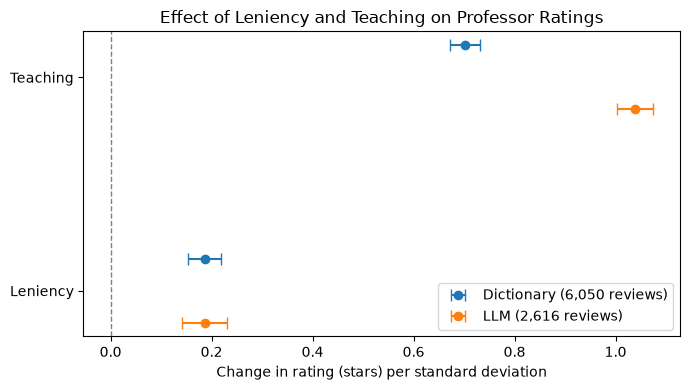

,(1) Dictionary,(2) LLM,"(3) Dictionary, same reviews","(4) LLM, same reviews"
Leniency (std.),0.186***,0.186***,0.258***,0.177***
Teaching (std.),0.702***,1.038***,0.686***,1.019***
Difficulty,-0.273***,-0.115***,-0.209***,-0.101**
STEM,0.02,-0.053,-0.138,-0.03
Social Science,0.099*,0.029,0.007,0.032
Teaching minus leniency,0.515***,0.852***,0.427***,0.842***
Reviews,6050,2616,700,700
R-squared,0.419,0.696,0.399,0.674


\begin{tabular}{lllll}
\toprule
 & (1) Dictionary & (2) LLM & (3) Dictionary, same reviews & (4) LLM, same reviews \\
\midrule
Leniency (std.) & 0.186*** & 0.186*** & 0.258*** & 0.177*** \\
Teaching (std.) & 0.702*** & 1.038*** & 0.686*** & 1.019*** \\
Difficulty & -0.273*** & -0.115*** & -0.209*** & -0.101** \\
STEM & 0.02 & -0.053 & -0.138 & -0.03 \\
Social Science & 0.099* & 0.029 & 0.007 & 0.032 \\
Teaching minus leniency & 0.515*** & 0.852*** & 0.427*** & 0.842*** \\
Reviews & 6050 & 2616 & 700 & 700 \\
R-squared & 0.419 & 0.696 & 0.399 & 0.674 \\
\bottomrule
\end{tabular}



,(1) Main model,(2) Without difficulty,(3) All reviews
Leniency (std.),0.186***,0.316***,0.091***
Teaching (std.),0.702***,0.723***,0.507***
Difficulty,-0.273***,,-0.445***
STEM,0.02,-0.096*,-0.108*
Social Science,0.099*,0.052,0.0
Teaching minus leniency,0.515***,0.407***,0.417***
Reviews,6050,6050,55773
R-squared,0.419,0.371,0.28


\begin{tabular}{llll}
\toprule
 & (1) Main model & (2) Without difficulty & (3) All reviews \\
\midrule
Leniency (std.) & 0.186*** & 0.316*** & 0.091*** \\
Teaching (std.) & 0.702*** & 0.723*** & 0.507*** \\
Difficulty & -0.273*** &  & -0.445*** \\
STEM & 0.02 & -0.096* & -0.108* \\
Social Science & 0.099* & 0.052 & 0.0 \\
Teaching minus leniency & 0.515*** & 0.407*** & 0.417*** \\
Reviews & 6050 & 6050 & 55773 \\
R-squared & 0.419 & 0.371 & 0.28 \\
\bottomrule
\end{tabular}



In [8]:
# ----- plot -----

variables = ['leniency_z', 'teaching_z']

# coefficients and 95% confidence intervals for each model
dict_coefs = dict_model.params[variables]
dict_ci = dict_model.conf_int().loc[variables]
llm_coefs = llm_model.params[variables]
llm_ci = llm_model.conf_int().loc[variables]

# distance from each coefficient to the ends of its confidence interval
dict_errors = [dict_coefs - dict_ci[0], dict_ci[1] - dict_coefs]
llm_errors = [llm_coefs - llm_ci[0], llm_ci[1] - llm_coefs]

fig, ax = plt.subplots(figsize=(7, 4))

# dictionary slightly above and llm slightly below each label
ax.errorbar(dict_coefs, [0.15, 1.15], xerr=dict_errors, fmt='o', capsize=4, label='Dictionary (6,050 reviews)')
ax.errorbar(llm_coefs, [-0.15, 0.85], xerr=llm_errors, fmt='o', capsize=4, label='LLM (2,616 reviews)')

# line at 0, anything to the right raises ratings
ax.axvline(0, color='grey', linestyle='--', linewidth=1)

ax.set_yticks([0, 1])
ax.set_yticklabels(['Leniency', 'Teaching'])
ax.set_xlabel('Change in rating (stars) per standard deviation')
ax.set_title('Effect of Leniency and Teaching on Professor Ratings')
ax.legend()
plt.tight_layout()
os.makedirs('../figures', exist_ok=True)
plt.savefig('../figures/regression_coefficients.png', dpi=300, bbox_inches='tight')
plt.show()

# ----- tables -----

# variables to show, with readable names
table_vars = {'leniency_z': 'Leniency (std.)',
              'teaching_z': 'Teaching (std.)',
              'difficulty': 'Difficulty',
              "C(dept_group, Treatment('Humanities'))[T.STEM]": 'STEM',
              "C(dept_group, Treatment('Humanities'))[T.Social Science]": 'Social Science'}

# stars for significance
def stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return ''

# one column per model, blank if the model doesn't include that variable
def model_column(model):
    column = []
    for var in table_vars:
        if var in model.params.index:
            coef = round(model.params[var], 3)
            column.append(str(coef) + stars(model.pvalues[var]))
        else:
            column.append('')

    # H3 test, how much larger teaching is than leniency
    h3_test = model.t_test('teaching_z - leniency_z = 0')
    difference = round(float(h3_test.effect[0]), 3)
    column.append(str(difference) + stars(float(h3_test.pvalue)))

    column.append(str(int(model.nobs)))
    column.append(str(round(model.rsquared, 3)))
    return column

# builds a table from a group of models
def build_table(models):
    row_names = []
    for name in table_vars.values():
        row_names.append(name)
    row_names.append('Teaching minus leniency')
    row_names.append('Reviews')
    row_names.append('R-squared')

    table = pd.DataFrame(index=row_names)
    for name in models:
        table[name] = model_column(models[name])
    return table

# ----- main table -----
main_models = {'(1) Dictionary': dict_model,
               '(2) LLM': llm_model,
               '(3) Dictionary, same reviews': dict_same_model,
               '(4) LLM, same reviews': llm_same_model}

main_table = build_table(main_models)
display(main_table)
print(main_table.to_latex())

# ----- robustness check table -----
robust_models = {'(1) Main model': dict_model,
                 '(2) Without difficulty': no_diff_model,
                 '(3) All reviews': all_model}

robust_table = build_table(robust_models)
display(robust_table)
print(robust_table.to_latex())